# **Requirments**

In [1]:
#requirments
# !pip install pytrends
# !pip install prophet
# !pip install scikit-learn 
# !pip install plotly 
# !pip install ipywidgets
# !pip install streamlit

# **Config**

In [2]:
#config
KEYWORD = "antique"
COUNTRY = "en-US" # "fr" for france 
WEIGHTS = { "search":0.6, "youtube":0.2, "news":0.2 }
WINDOWS = { "short":2, "medium":4, "long":8 }
FORECAST_DAYS = 90
SPIKE_THRESHOLD = 1.5
BUILD_THRESHOLD = 0.8
COLLAPSE_THRESHOLD = - 1.0
# STD_CUTOFF = 10
MAX_TRIES = 10
WAIT_SECONDS = 2
TIME_FRAME = "today 5-y"

# **Fetcher**

In [3]:
import requests
import time
import random
import pandas as pd
from pytrends.request import TrendReq
from pytrends import exceptions # Import exceptions module to catch TooManyRequestsError

def get_retry_wait(retries, wait_seconds):
    wait_time = min(wait_seconds * (2 ** retries) + random.uniform(0, 5), 120)
    return wait_time



def fetch_trends(KEYWORD, gprop="", hl="fr", time_frame =TIME_FRAME):
  """
    Fetches Google Trends data for a list of keywords.
    gprop: "" (web), "youtube", or "news"
    Returns a raw wide dataframe.

  """

  pytrends = TrendReq( timeout = (10,20),
                      hl="fr", 
                       )
  
  
  retries = 0
  wait = get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS)

  for attempt in range(1, MAX_TRIES+1 ):
    try :
      print(f"\nSending request for : {KEYWORD}\nSource : {gprop}")
      # Pass KEYWORD as a list to pytrends.build_payload
      pytrends.build_payload([KEYWORD] ,
                            gprop= gprop,
                            timeframe = time_frame
                            )
      iot = pytrends.interest_over_time()
      if iot.empty:
        # If empty, raise ValueError to trigger retry logic or final return
        raise ValueError("Empty Dataframe received from pytrends.")
      else:
        print("✅ Success")
        time.sleep(wait)
        return iot
    except exceptions.TooManyRequestsError as e:
        # This specifically handles the 429 error raised by pytrends when rate-limited
        retries += 1      
        wait = get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS)
        print(f"⚠️ 429 Rate limit (PytrendsError). Retrying in {wait:.0f}s. Attempt {retries}/{MAX_TRIES}")
        time.sleep(wait)
    except requests.exceptions.HTTPError as e:
        # This handles general HTTP errors not specifically caught by pytrends.exceptions
        status = e.response.status_code if e.response is not None else None
        retries += 1

        if status == 429:
            wait = get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS)
            print(f"⚠️ 429 Rate limit (HTTPError). Retrying in {wait:.0f}s. Attempt {retries}/{MAX_TRIES}")
            time.sleep(wait)
        elif status == 500:
            wait = get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS)
            print(f"⚠️ 500 Google error. Retrying in {wait:.0f}s. Attempt {retries}/{MAX_TRIES}")
            time.sleep(wait)
        elif status == 400:
            print("⚠️ 400 Bad request")
            print("❌ Unknown HTTP error:", e)
            returnr("Wrong Keyword or bad request from HTTPError.")
        else:
            wait = get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS)
            print(f"❌ Unknown HTTP error: {e}. Retrying in {wait:.0f}s. Attempt {retries}/{MAX_TRIES}")
            time.sleep(wait)
            
    except ValueError as e: # Catch the ValueError for "Empty Dataframe"
        retries += 1
        wait = get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS)
        print(f"⚠️ {e}. Retrying in {wait:.0f}s. Attempt {retries}/{MAX_TRIES}")
        time.sleep(wait)
        
    except Exception as e:
        # Catch any other unexpected errors
        retries += 1
        wait = get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS)
        print(f"❌ An unexpected error occurred: {e}. Retrying in {wait:.0f}s. Attempt {retries}/{MAX_TRIES}")
        time.sleep(wait)

  print(f"❌ Max retries ({MAX_TRIES}) reached for KEYWORD: {KEYWORD}. Returning empty DataFrame.")
  # If all retries fail, return an empty DataFrame with the expected columns
  # so subsequent operations like prepare_df don't fail immediately due to missing columns.
  # `isPartial` is expected by `prepare_df` to be dropped.
  return pd.DataFrame(columns=['date', KEYWORD, 'isPartial'])

# Calling fetch_treds function
# search_df = fetch_trends(KEYWORD, gprop="")
# youtube_df = fetch_trends(KEYWORD, gprop="youtube")
# news_df = fetch_trends(KEYWORD, gprop="news")

In [4]:
# import requests
# import time
# import random
# import pandas as pd
# from pytrends.request import TrendReq
# from pytrends import exceptions # Import exceptions module to catch TooManyRequestsError

# def get_retry_wait(retries, wait_seconds):
#     wait_time = min(wait_seconds * (2 ** retries) + random.uniform(0, 5), 120)
#     return wait_time

# def fetch_trends(KEYWORD, gprop="", hl="fr", time_frame ="TIME_FRAME"):
#   """
#     Fetches Google Trends data for a list of keywords.
#     gprop: "" (web), "youtube", or "news"
#     Returns a raw wide dataframe.

#   """

#   pytrends = TrendReq( timeout = (10,20),
#                       hl="fr", 
#                        )
#   pytrends.build_payload([KEYWORD], geo=geo, timeframe=TIME_FRAME)
#   related = pytrends.related_queries()

  
#   retries = 0
#   wait = get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS)

#   data = related.get(keyword, {})
#   top_df = data.get("top")
#   rising_df = data.get("rising")

#   for attempt in range(1, MAX_TRIES+1 ):
#     try :
#       print(f"\nSending request for : {KEYWORD}\nSource : {gprop}")
#       # Pass KEYWORD as a list to pytrends.build_payload
#     #   pytrends.build_payload([KEYWORD] ,
#     #                         gprop= gprop,
#     #                         timeframe = time_frame
#     #                         )
#     #   iot = pytrends.interest_over_time()


#       if related.empty:
#         # If empty, raise ValueError to trigger retry logic or final return
#         raise ValueError("Empty Dataframe received from pytrends.")
#       else:
#         print("✅ Success")
#         time.sleep(wait)
#         return {
#                 "top": top_df,
#                 "rising": rising_df
#             }
#     except exceptions.TooManyRequestsError as e:
#         # This specifically handles the 429 error raised by pytrends when rate-limited
#         retries += 1
#         wait        
#         print(f"⚠️ 429 Rate limit (PytrendsError). Retrying in {wait:.0f}s. Attempt {retries}/{MAX_TRIES}")
#         time.sleep(get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS))
#     except requests.exceptions.HTTPError as e:
#         # This handles general HTTP errors not specifically caught by pytrends.exceptions
#         status = e.response.status_code if e.response is not None else None
#         retries += 1

#         if status == 429:
#             wait
#             print(f"⚠️ 429 Rate limit (HTTPError). Retrying in {wait:.0f}s. Attempt {retries}/{MAX_TRIES}")
#             time.sleep(wait)
#         elif status == 500:
#             wait
#             # wait = min(wait_seconds * (2 ** retries) + random.uniform(0, 5), 120)
#             # get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS)
#             print(f"⚠️ 500 Google error. Retrying in {wait:.0f}s. Attempt {retries}/{MAX_TRIES}")
#             # time.sleep(get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS))
#             time.sleep(wait)
#         elif status == 400:
#             print("⚠️ 400 Bad request. Skipping.")
#             print("❌ Unknown HTTP error:", e)
#             raise ValueError("Wrong Keyword or bad request from HTTPError.") # Re-raise for immediate stop
#         else:
#             wait = min(wait_seconds * (2 ** retries) + random.uniform(0, 5), 120)
#             get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS)
#             print(f"❌ Unknown HTTP error: {e}. Retrying in {wait:.0f}s. Attempt {retries}/{MAX_TRIES}")
#             time.sleep(get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS))
#     except ValueError as e: # Catch the ValueError for "Empty Dataframe"
#         retries += 1
#         wait = min(wait_seconds * (2 ** retries) + random.uniform(0, 5), 120)
#         get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS)
#         print(f"⚠️ {e}. Retrying in {wait:.0f}s. Attempt {retries}/{MAX_TRIES}")
#         time.sleep(get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS))
  
#     except Exception as e:
#         # Catch any other unexpected errors
#         retries += 1
#         wait = min(wait_seconds * (2 ** retries) + random.uniform(0, 5), 120)
#         print(f"❌ An unexpected error occurred: {e}. Retrying in {wait:.0f}s. Attempt {retries}/{MAX_TRIES}")
#         time.sleep(get_retry_wait(retries=retries, wait_seconds=WAIT_SECONDS))
        
#   print(f"❌ Max retries ({MAX_TRIES}) reached for KEYWORD: {KEYWORD}. Returning empty DataFrame.")
#   # If all retries fail, return an empty DataFrame with the expected columns
#   # so subsequent operations like prepare_df don't fail immediately due to missing columns.
#   # `isPartial` is expected by `prepare_df` to be dropped.
#   return pd.DataFrame(columns=['date', KEYWORD, 'isPartial'])

# # Calling related treds function
# result = fetch_related(keyword_list[0])

# top_queries = result["top"]
# rising_queries = result["rising"]
# top = top_queries[:4]
# rising = rising_queries[:4]

# print(f"Top related queries: {top}")
# print(f"Rising related queries {rising}")

# **Cleaner**

In [8]:
# cleaner
def prepare_df(df, source, keyword):
    df_copy = df.copy()
    df_copy.reset_index(inplace=True)

    # Remove columns if it exists
    columns_to_drop = ["isPartial", "index", "level_0", ""]
    for col in df_copy.columns:
        if col in columns_to_drop:
            df_copy = df_copy.drop(columns=[col])

    # Make sure date is datetime
    df_copy["date"] = pd.to_datetime(df_copy["date"])

    # Add metadata
    df_copy["source"] = source

    return df_copy

# Usage 

# cleaned_search = prepare_df(search_df, "search", KEYWORD)
# cleaned_youtube = prepare_df(youtube_df, "youtube", KEYWORD)
# cleaned_news = prepare_df(news_df, "news", KEYWORD)

# cleaned_search.head()

# combined_df = pd.concat(
#     [cleaned_search, cleaned_youtube, cleaned_news],
#     ignore_index=True
# )

# combined_df = combined_df.sort_values("date").reset_index(drop=True)
# combined_df

In [4]:
# if combined_df.notna().any():
#     combined_df.to_csv(f"/home/szasz/Documents/CS/code/signal_flow/combined_trends_{KEYWORD}.csv", index=False)


# **Compositer**

In [5]:
def composite(df):

    df_y = (df
        .assign(y=df[KEYWORD] * df['source'].map(WEIGHTS))
        .groupby('date', as_index=False)['y']
        .sum()
        .rename(columns={"date": "ds"})
        )
    df_y["ds"] = pd.to_datetime(df_y["ds"]) 

    return df_y 


# **Velocity**

In [ ]:
import pandas as pd
from scipy.stats import median_abs_deviation, norm

def robust_zscore(serise):
  serise = serise.astype(float)
  median = serise.median()
  mad = max(median_abs_deviation(serise, nan_policy="omit"), 1e-6)
  return (serise - median) / mad

    # Compute the Median Absolute Deviation (MAD), a robust measure of spread
    # similar to standard deviation but less sensitive to outliers.
    # Ensure MAD is never too close to zero.
    # max(..., 1e-6) sets a minimum value of 0.000001.
    #
    # Why?
    # - If all values in the series are identical (or nearly identical),
    #   MAD can become 0.
    # - Later calculations may divide by MAD.
    # - Division by 0 would cause errors or extremely unstable values.
    #
    # Using a tiny floor value (1e-6) prevents numerical instability.


def velocity (df, WINDOWS):

  df = df.copy()

  df["short_velocity"] = df["y"].rolling(WINDOWS['short']).mean().diff()
  df["medium_velocity"] = df["y"].rolling(WINDOWS['medium']).mean().diff()
  df["long_velocity"] = df["y"].rolling(WINDOWS['long']).mean().diff()

  df["y_zscore"] = robust_zscore(df["y"])
  df["short_velocity_zscore"] = df["y_zscore"].rolling(WINDOWS['short']).mean().diff()
  df["medium_velocity_zscore"] = df["y_zscore"].rolling(WINDOWS['medium']).mean().diff()
  df["long_velocity_zscore"] = df["y_zscore"].rolling(WINDOWS['long']).mean().diff()

  # df = df.dropna(subset= ['short_velocity', 'medium_velocity', 'long_velocity',
  #      'y_zscore', 'short_velocity_zscore', 'medium_velocity_zscore',
  #      'long_velocity_zscore'])

  return df

# Usage 
# velocity_df = velocity(composite_df, WINDOWS)
# velocity_df.head(10)

# **Regime**

In [ ]:
def classify_regime (row, 
                    spike_threshold = SPIKE_THRESHOLD,
                    building_threshhold = BUILD_THRESHOLD,
                    collapse_threshold = SPIKE_THRESHOLD
                    ):
    sz = row["short_velocity_zscore"]
    lz = row["long_velocity_zscore"]

    if pd.isna(sz):
        return "Insufficient Data"

    crossover = (sz - lz) if pd.notna(lz) else 0

    if sz > spike_threshold and crossover >= 0:
        return "Spike"
    
    elif sz > building_threshhold and crossover >= 0:
        return "Building"
    
    elif sz < -collapse_threshold or ((pd.notna(lz)) and crossover < -1 and lz > 0 ):
        return "Collapsing"

    else :
        return "Quiet"

# Usage     
# velocity_df["regime"] = velocity_df.apply(classify_regime, axis = 1) 
# velocity_df["regime"].value_counts()
# velocity_df.head()

# **Forecaster**

In [20]:
import pandas as pd
from prophet import Prophet
from prophet.plot import plot_plotly
import plotly.io as pio
pio.renderers.default = 'notebook'   # or 'colab' for Google Colab


def forecaster(df):

    print(df.head(10))
    print(df.tail(10))
    print("Any NaNs?", df.isna().any())
    print("Any zeros?", (df['y'] == 0).sum())
    
    model = Prophet(
        daily_seasonality = "auto",
        weekly_seasonality = True,
        yearly_seasonality = True
    )
    model.fit(df)

    future = model.make_future_dataframe(periods= FORECAST_DAYS, freq="W")
    forecast_full = model.predict(future)
    forecast = forecast_full[['ds', 'yhat', 'yhat_lower', 'yhat_upper']]

    # Figures
    fig1 = model.plot(forecast_full)
    fig2 = model.plot_components(forecast_full)
    fig3 = plot_plotly(model, forecast_full)


    return future, forecast, fig1 , fig2, fig3

# usage 
# future_df , forecast_df, fig1, fig2, fig3 = forecaster(composite_df)

In [21]:
# future_df.head()

In [22]:
# forecast_df.head()

In [23]:
# fig1

In [24]:
# fig2

In [25]:
# fig3

# **Charts**

In [26]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

def plot_singals ():
    
        fig, ax = plt.subplots(figsize=(15,5))

        ax.plot(cleaned_search["date"], cleaned_search[KEYWORD], 
                color= "steelblue", linewidth= 2, label = "google search"
                )
        ax.plot(cleaned_youtube["date"], cleaned_youtube[KEYWORD],
                color= "tomato", linewidth=2, label= "youtube" 
                )
        ax.plot(cleaned_news["date"], cleaned_news[KEYWORD],
                color= "goldenrod", linewidth= 2, label= "news"
                )
        
        ax.set_title(f"Signal comparison of: {KEYWORD} ")
        ax.set_ylabel("Trend Score %")
        ax.set_xlabel("Dates")
        ax.legend()
        ax.grid(alpha= 0.3)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
        plt.xticks(rotation= 45)
        plt.tight_layout()
   
        return fig

In [27]:
# fig4 = plot_singals()
# fig4

In [28]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates

def regime_chart(df):
    cutoff_date = df["ds"].max() - pd.Timedelta(days= FORECAST_DAYS)

    regime_colors = {
        "Spike":             "#c8f7c5",
        "Building":          "#fef9c3",
        "Quiet":             "#f0f0f0",
        "Collapsing":        "#fdd",
        "Insufficient Data": "#ffffff"
    }

    fig, (ax1, ax2) = plt.subplots(
            2, 1,
            figsize= (14, 7),
            sharex= True,
            gridspec_kw= {"height_ratios": [2,1]}
    )

    # Background regime shade 
    for i in range (len(df["regime"]) - 1):

        regime = df["regime"].iloc[i]
        ax1.axvspan(
            df["ds"].iloc[i],
            df["ds"].iloc[i + 1],
            color= regime_colors.get(regime, "#ffffff")
        )
    
    # Main trend line
    ax1.plot(
        df["ds"],
        df["y"],
        color= "#1a1a2e",
        linewidth= 4,
        label = "Trend Score"
    )
    ax1.set_ylabel("Trend Score")
    ax1.set_title(
        f"Regime Classification - Last 90 Days for {KEYWORD}",
        fontsize= 14,
        fontweight= "bold"
    )
    ax1.grid(alpha= 0.3)

    
    # Z-Score Velocity 
    ax2.plot(
        df["ds"],
        df["short_velocity_zscore"],
        color= "tomato",
        linewidth= 2,
        label= f"Short Z-score"
    )

    ax2.plot(
        df["ds"],
        df["long_velocity_zscore"],
        color= "steelblue",
        linewidth= 2,
        label= "Long Z-score"
    )

    ax2.axhline(
        y=SPIKE_THRESHOLD,
        color= "green",
        linestyle= "--",
        alpha = 0.7,
        linewidth= 1,
        label= f"Spike Threshold (Z={SPIKE_THRESHOLD})"
    )

    ax2.axhline(
        y= COLLAPSE_THRESHOLD,
        color= "red",
        linestyle= "--",
        alpha= 0.7,
        linewidth= 1,
        label= f"Building Threshold (Z={BUILD_THRESHOLD})"
    )

    ax2.axhline(
        y= 0,
        color= "gray",
        linestyle= "-",
        alpha= 0.7,
        linewidth= 1
    )

    ax2.set_ylabel("Z-Score")
    ax2.set_xlabel("Date")
    ax2.legend(fontsize= 10)
    ax2.grid(alpha= 0.3)

    # Regime legend
    patches = [
        mpatches.Patch(color="#c8f7c5", label="Spike: Act Now"),
        mpatches.Patch(color="#fef9c3", label="Building: Watch"),
        mpatches.Patch(color="#f0f0f0", label="Quiet: Wait"),
        mpatches.Patch(color="#fdd",    label="Collapsing: Hold")
    ]
    
    ax1.legend(handles=patches, loc="upper left", fontsize=10)
    
    ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

    plt.xticks(rotation= 45)
    plt.tight_layout()

    return fig



# regime_chart(velocity_df)

# **Save to PDF**

In [ ]:
# from matplotlib.backends.backend_pdf import PdfPages
# import matplotlib.pyplot as plt 

# with PdfPages(f"{KEYWORD}_report.pdf") as pdf:

#     regime_plot_save = regime_chart(velocity_df)
#     signals_plot_save = plot_singals()

#     pdf.savefig(regime_plot_save)
#     pdf.savefig(signals_plot_save)
#     pdf.savefig(fig1)
#     pdf.savefig(fig2)

#     plt.close(regime_plot_save)
#     plt.close(singals_plot_save)
#     plt.close(fig1)
#     plt.close(fig2)
#     print("All charts saved sucessfully!")

# main

In [30]:
# import pandas as pd

# # from config import KEYWORD, WINDOWS
# # from fetcher import fetch_trends
# # from cleaner import prepare_df
# # from compositor import composite
# # from velocity import velocity
# # from regime import classify_regime
# # from forecaster import forecaster
# # from charts import plot_composite_trend, plot_regime_timeline, plot_velocity_zscores
# # from report import save_charts_to_pdf


# def fetch_raw(keyword):
#     """The slow, rate-limited part — hits Google Trends three times."""
#     search_df = fetch_trends(keyword, gprop="")
#     youtube_df = fetch_trends(keyword, gprop="youtube")
#     news_df = fetch_trends(keyword, gprop="news")

#     cleaned_search = prepare_df(search_df, "search", keyword)
#     cleaned_youtube = prepare_df(youtube_df, "youtube", keyword)
#     cleaned_news = prepare_df(news_df, "news", keyword)
#     return pd.concat([cleaned_search, cleaned_youtube, cleaned_news])


# def process_pipeline(combined_df):
#     """Everything downstream — fast, local, no network calls."""
#     composite_df = composite(combined_df)
#     velocity_df = velocity(composite_df, WINDOWS)
#     velocity_df["regime"] = velocity_df.apply(classify_regime, axis=1)
#     future_df, forecast_df, fig1, fig2, fig3 = forecaster(composite_df)

#     return {
#         "composite_df": composite_df,
#         "velocity_df": velocity_df,
#         "forecast_df": forecast_df,
#         "future_df": future_df,
#         "fig1": fig1, "fig2": fig2, "fig3": fig3,
#     }


# def run_pipeline(keyword=KEYWORD, save_report=True):
#     combined_df = fetch_raw(keyword)
#     results = process_pipeline(combined_df)

#     if save_report:
#         figures = [
#             plot_composite_trend(results["composite_df"]),
#             plot_regime_timeline(results["velocity_df"]),
#             plot_velocity_zscores(results["velocity_df"]),
#             results["fig1"],
#             results["fig2"],
#         ]
#         save_charts_to_pdf(figures, f"reports/{keyword}_signal_flow_report.pdf")

#     return results


# if __name__ == "__main__":
#     run_pipeline()


Sending request for : antique
Source : 
✅ Success

Sending request for : antique
Source : youtube
✅ Success

Sending request for : antique
Source : news
✅ Success


16:08:31 - cmdstanpy - INFO - Chain [1] start processing
16:08:31 - cmdstanpy - INFO - Chain [1] done processing


          date  antique   source
0   2021-08-08       37   search
1   2021-08-08       29  youtube
2   2021-08-08       27     news
3   2021-08-15       40   search
4   2021-08-15       27  youtube
..         ...      ...      ...
781 2026-08-02       40   search
782 2026-08-02       37  youtube
783 2026-08-09       30  youtube
784 2026-08-09       45   search
785 2026-08-09       53     news

[786 rows x 3 columns]
          ds     y
0 2021-08-08  33.4
1 2021-08-15  37.4
2 2021-08-22  27.4
3 2021-08-29  26.2
4 2021-09-05  38.4
          ds     y  short_velocity  medium_velocity  long_velocity  y_zscore  \
0 2021-08-08  33.4             NaN              NaN            NaN  0.341463   
1 2021-08-15  37.4             NaN              NaN            NaN  1.317073   
2 2021-08-22  27.4            -3.0              NaN            NaN -1.121951   
3 2021-08-29  26.2            -5.6              NaN            NaN -1.414634   
4 2021-09-05  38.4             5.5             1.25            NaN

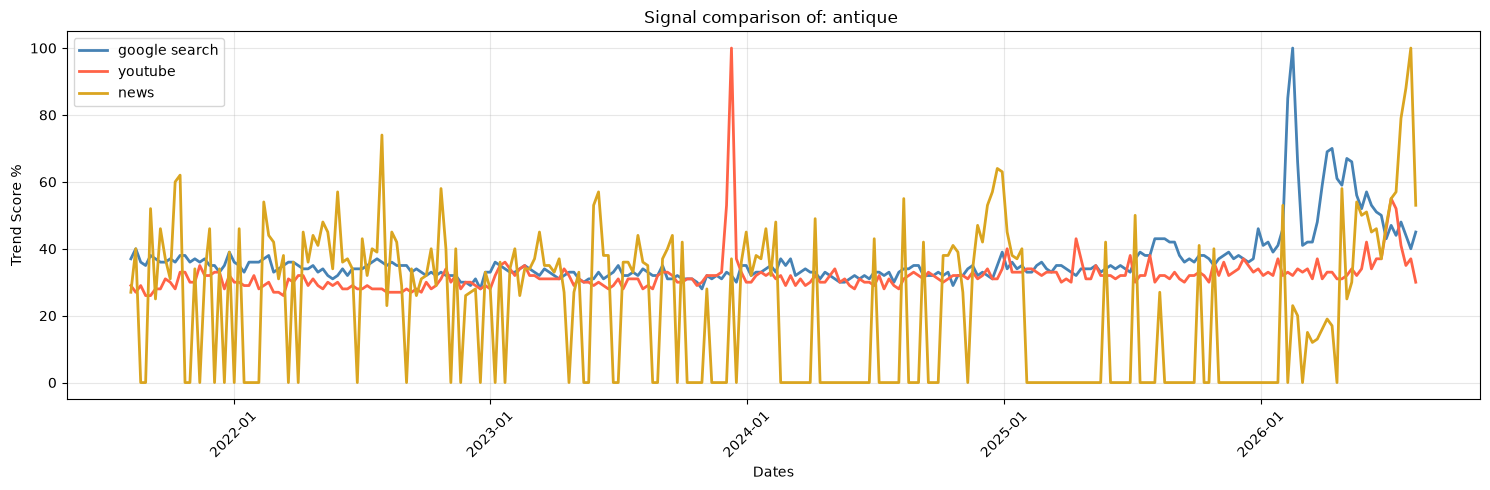

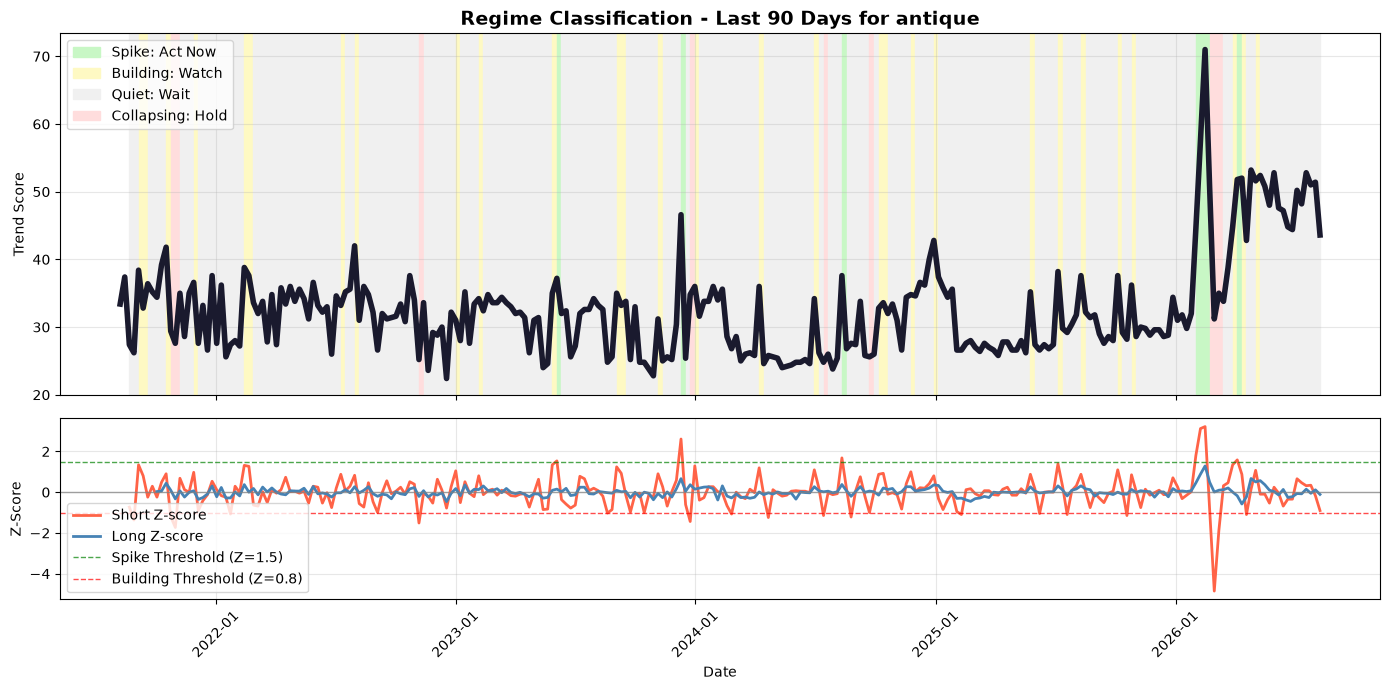

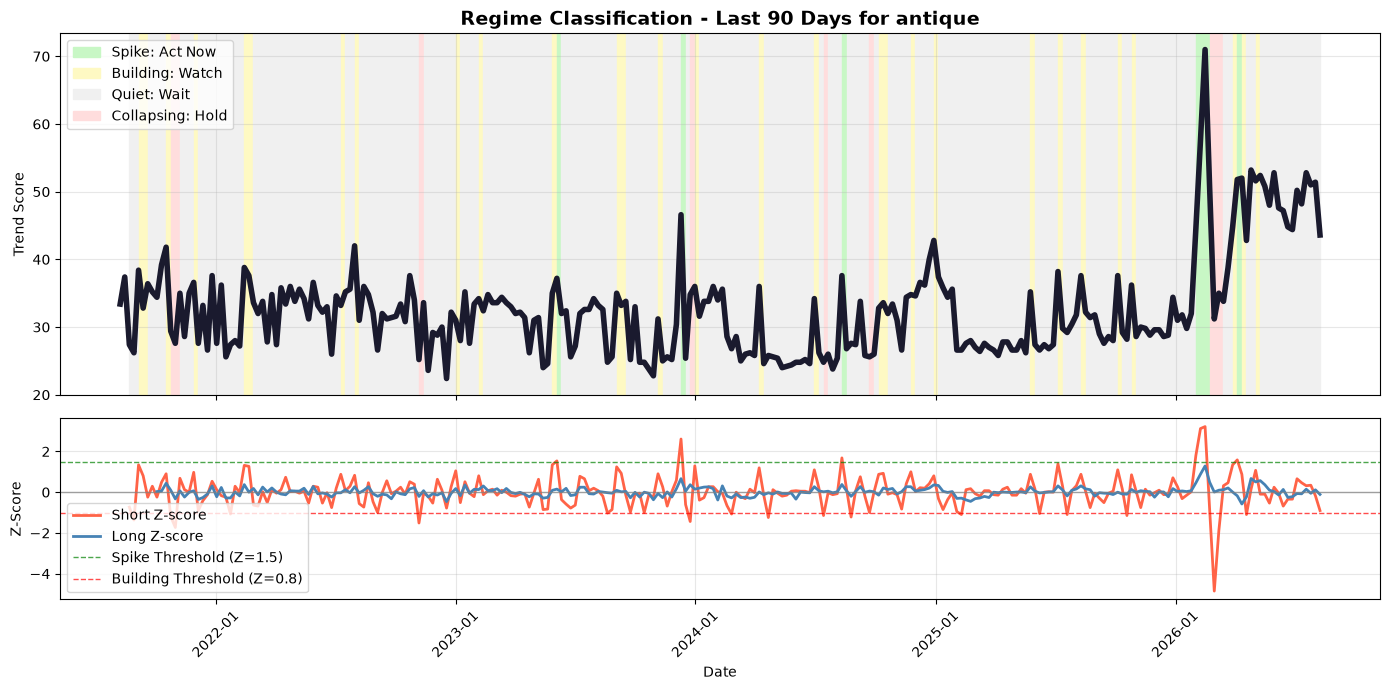

In [35]:
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt 


# Fetch query form pytrends  

search_df = fetch_trends(KEYWORD, gprop="")
youtube_df = fetch_trends(KEYWORD, gprop="youtube")
news_df = fetch_trends(KEYWORD, gprop="news")

# Fetch recommended queries 

# Clean dataframe 
cleaned_search = prepare_df(search_df, "search", KEYWORD)
cleaned_youtube = prepare_df(youtube_df, "youtube", KEYWORD)
cleaned_news = prepare_df(news_df, "news", KEYWORD)


# Combine dataframe
combined_df = pd.concat(
    [cleaned_search, cleaned_youtube, cleaned_news],
    ignore_index=True
)

combined_df = combined_df.sort_values("date").reset_index(drop=True)
print(combined_df)

# Save dataframe 
combined_df.to_csv(f"/home/szasz/Documents/CS/code/signal_flow/combined_trends_{KEYWORD}.csv", index=False)

# Join the dtaframes with "ds" and "y" columns
composite_df = composite(combined_df)
print(composite_df.head())

# Get velocity and Z-score
velocity_df = velocity(composite_df, WINDOWS)
print(velocity_df.head(10))


# Get regime 
velocity_df["regime"] = velocity_df.apply(classify_regime, axis = 1) 
print(f" regime value counts {velocity_df["regime"].value_counts()}")
print(velocity_df.head())

# Forecasting 
future_df , forecast_df, fig1, fig2, fig3 = forecaster(composite_df)

# Plotting 
# Plotting three singals 
three_singal_plot = plot_singals()
fig4 = three_singal_plot

# Regime plot
regime_plot = regime_chart(velocity_df)

# Save plots to pdf 
with PdfPages(f"{KEYWORD}_report.pdf") as pdf:

    three_singal_plot = regime_chart(velocity_df)
    regime_plot = plot_singals()

    pdf.savefig(three_singal_plot)
    pdf.savefig(regime_plot)
    pdf.savefig(fig1)
    pdf.savefig(fig2)

    plt.close(regime_plot_save)
    plt.close(regime_plot)
    plt.close(fig1)
    plt.close(fig2)
    print("All charts saved sucessfully!")

In [38]:
import streamlit as st

st.set_page_config(page_title="Signal Flow Pro", layout="wide")
st.title("📊 Signal Flow Pro")
st.caption("Composite trend, regime detection, and forecast for a Google Trends keyword.")

keyword = st.sidebar.text_input("Keyword", value=KEYWORD)
fetch_button = st.sidebar.button("Fetch & run")

# Only fetch_raw() is cached — it's the slow, rate-limited network step.
# process_pipeline() reruns fresh every time: it's cheap local computation,
# and it sidesteps caching matplotlib/plotly figure objects entirely.
@st.cache_data(ttl=3600, show_spinner="Fetching Google Trends data...")
def cached_fetch(kw):
    return fetch_raw(kw)

if "combined_df" not in st.session_state:
    st.session_state["combined_df"] = None
    st.session_state["keyword"] = None

if fetch_button:
    st.session_state["combined_df"] = cached_fetch(keyword)
    st.session_state["keyword"] = keyword

if st.session_state["combined_df"] is None:
    st.info("Enter a keyword and click **Fetch & run** to get started.")
    st.stop()

with st.spinner("Building composite index, regime, and forecast..."):
    results = process_pipeline(st.session_state["combined_df"])

velocity_df = results["velocity_df"]
composite_df = results["composite_df"]

latest = velocity_df.iloc[-1]
col1, col2, col3 = st.columns(3)
col1.metric("Current regime", latest["regime"])
col2.metric("Composite index", f"{latest['y']:.1f}")
col3.metric("Short-term z-score", f"{latest['short_velocity_zscore']:.2f}")

st.subheader("Forecast")
st.plotly_chart(results["fig3"], use_container_width=True)

st.subheader("Regime timeline")
st.pyplot(plot_regime_timeline(velocity_df))

st.subheader("Recent history")
st.dataframe(
    velocity_df[["ds", "y", "short_velocity_zscore", "long_velocity_zscore", "regime"]].tail(15),
    use_container_width=True,
)

st.subheader("Report")
if st.button("Generate PDF report"):
    figures = [
        plot_composite_trend(composite_df),
        plot_regime_timeline(velocity_df),
        plot_velocity_zscores(velocity_df),
        results["fig1"],
        results["fig2"],
    ]
    output_path = f"reports/{st.session_state['keyword']}_signal_flow_report.pdf"
    save_charts_to_pdf(figures, output_path)
    with open(output_path, "rb") as f:
        st.download_button("Download PDF", data=f,
                            file_name=output_path.split("/")[-1], mime="application/pdf")

2026-08-09 16:11:03.873 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-09 16:11:03.874 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-09 16:11:03.943 
  command:

    streamlit run /home/szasz/Documents/CS/venv/lib/python3.14/site-packages/ipykernel_launcher.py [ARGUMENTS]
2026-08-09 16:11:03.945 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-09 16:11:03.946 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-09 16:11:03.947 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-09 16:11:03.948 Thread 'MainThread': missing ScriptRunContext! This warning can be i

NameError: name 'process_pipeline' is not defined